# 1 Data Loading and Initial Inspection
---
Key takeaways:
- 7 features and datetime, 69,680 rows.
- Timestamps are 15 minute intervals.
- There are no missing or duplicate timestamps.
- There are no missing values.


## 1.1 Libraries and Formatting

### 1.1.1 Packages

In [4]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [5]:
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
from src.figures_cfg import apply_theme, plot_feature_ts, plot_features_ts, plot_correlation_matrix, plot_seasonal, plot_seasonal_grid, plot_monthly_box

### 1.1.2 Theme

In [6]:
apply_theme()
PRIMARY = "#003366"
MUTED   = "#6E7888"
INK     = "#121826"
LIGHT   = "#F0F2F5"

FEATURE_COLOURS = {
    'HUFL': '#003366',  # dark navy
    'HULL': '#1a5276',  # deep blue
    'MUFL': '#2e86c1',  # mid blue
    'MULL': '#5d6d7e',  # blue-grey
    'LUFL': '#85929e',  # mid grey
    'LULL': '#aab7b8',  # light grey
    'OT':   '#c0392b',  # red accent
}

### 1.1.3 Load Data

In [7]:
# Set date as index.
df = pd.read_csv(PROJECT_ROOT / "data" / "raw"/ "ETTh1.csv", parse_dates=["date"], index_col="date")

---

## 1.2 Data Shape and Head

In [8]:
# Count rows and columns.
df.shape

(17420, 7)

In [9]:
df.head()

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
date,,,,,,,
2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


## 1.3 Data Types

In [10]:
df.dtypes

HUFL    float64
HULL    float64
MUFL    float64
MULL    float64
LUFL    float64
LULL    float64
OT      float64
dtype: object

## 1.4 Date Validation

In [11]:
full_date_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq="1h")

assert all(full_date_range == df.index)

## 1.5 Missing Values

In [12]:
df.isnull().sum().sum()

np.int64(0)

In [13]:
df.describe()

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
count,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000
mean,7.375141,2.242242,4.300239,0.881568,3.066062,0.856932,13.324672
std,7.067744,2.042342,6.826978,1.809293,1.164506,0.599552,8.566946
min,-22.705999,-4.756000,-25.087999,-5.934000,-1.188000,-1.371000,-4.080000
25%,5.827000,0.737000,3.296000,-0.284000,2.315000,0.670000,6.964000
50%,8.774000,2.210000,5.970000,0.959000,2.833000,0.975000,11.396000
75%,11.788000,3.684000,8.635000,2.203000,3.625000,1.218000,18.079000
max,23.643999,10.114000,17.341000,7.747000,8.498000,3.046000,46.007000


---

# 2 Descriptive Statistics

---

## 2.1 Correlation Matrix

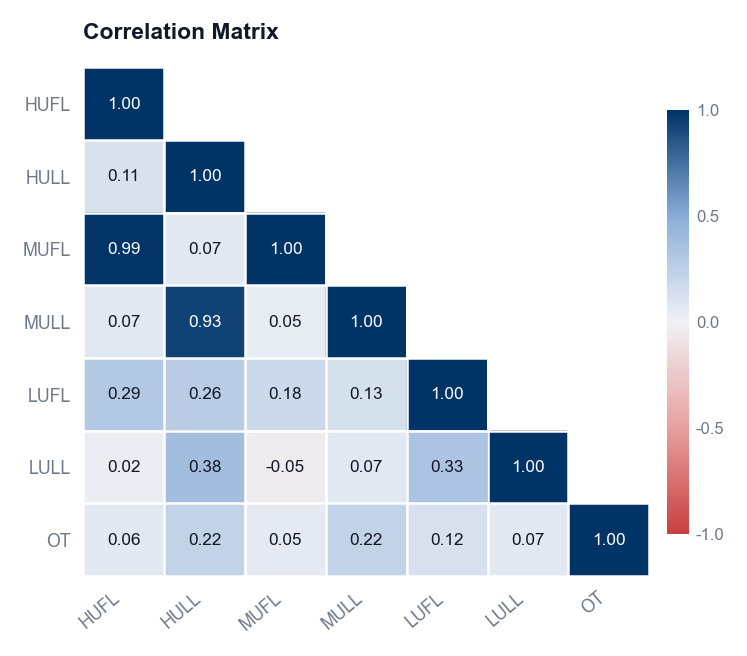

In [14]:
fig = plot_correlation_matrix(df, title="Correlation Matrix", mask_upper=True)
# fig.savefig("../figures/eda/correlation-matrix.png")
plt.show()

---

# 3 Time Series Visualisation
---
Key takeaways:
- Negative overall trend for OT.
- OT peaks in summer months.
- OT has daily seasonality, with peaks around 15:00.



## 3.1 Complete Time Series Plots

### 3.1.1 Predictors

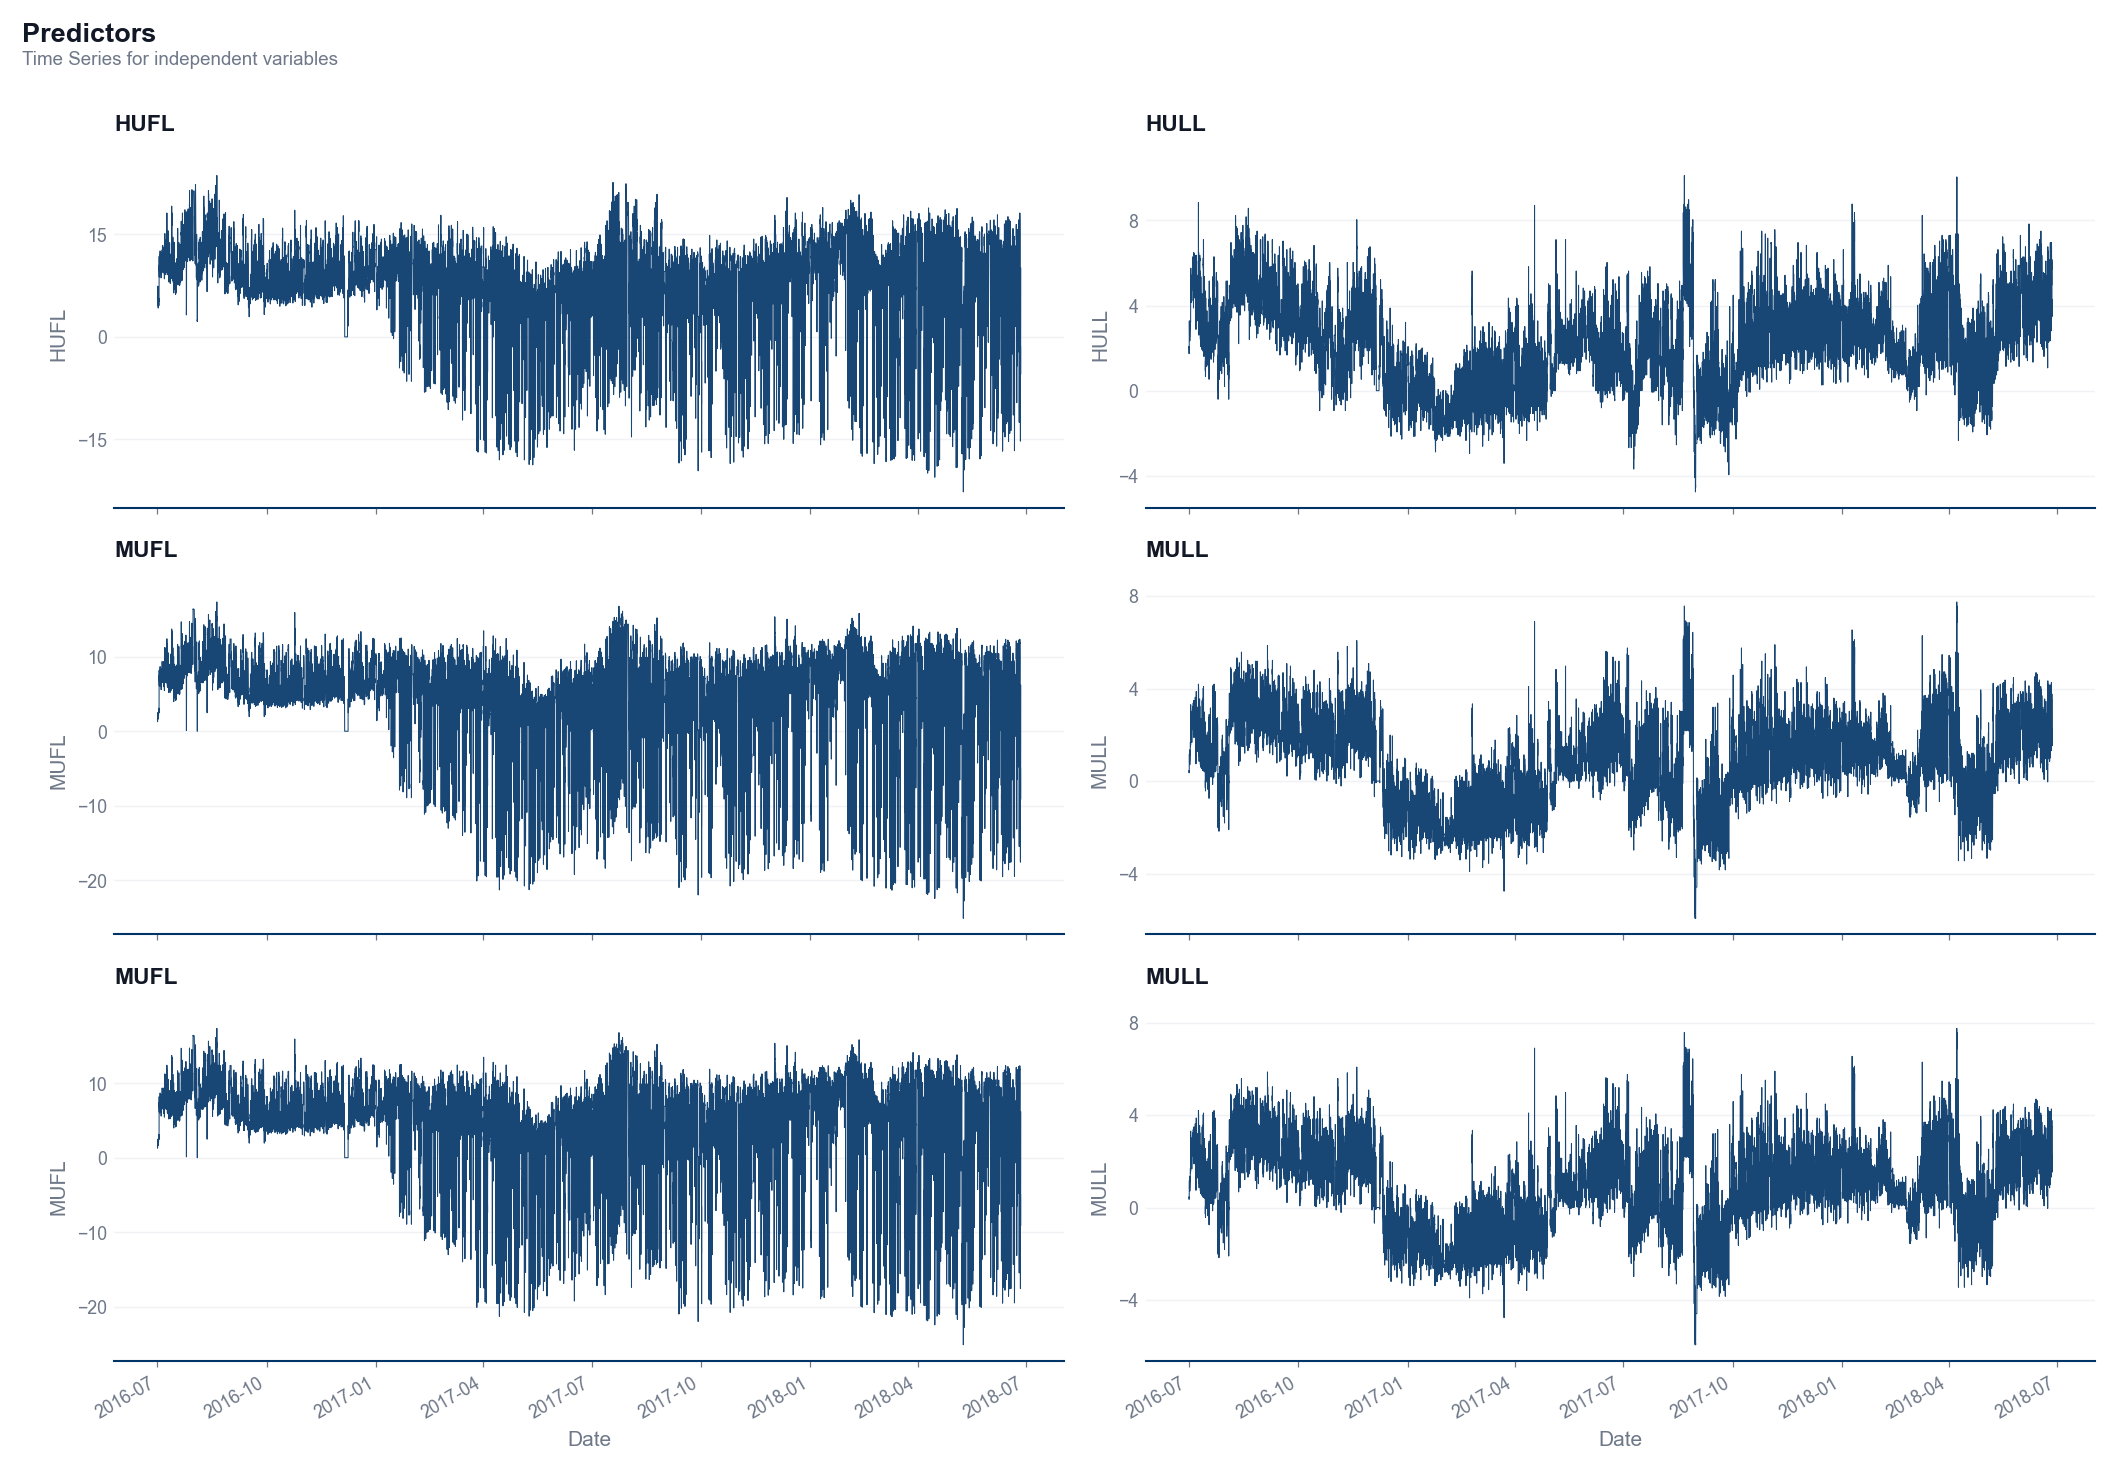

In [15]:
fig = plot_features_ts(df, ["HUFL", "HULL", "MUFL", "MULL", "MUFL", "MULL"], 3, 2, suptitle="Predictors", subtitle="Time Series for independent variables")
# fig.savefig("../figures/eda/predictor-time-series.png")

### 3.1.2 Independent Variable

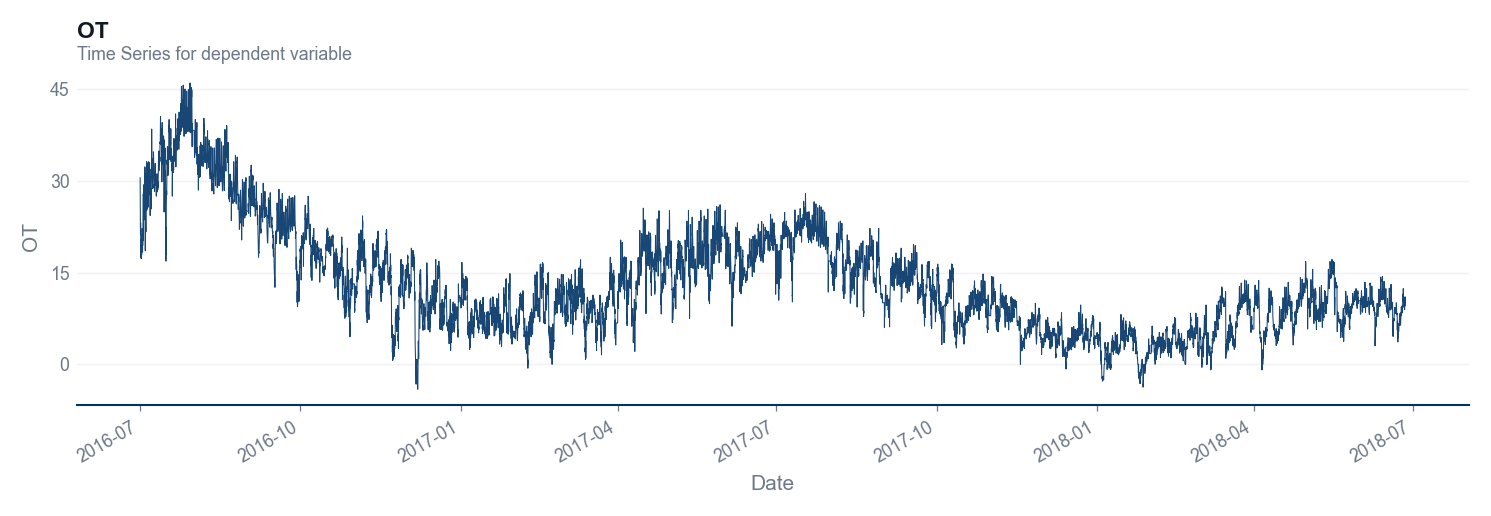

In [16]:
fig = plot_feature_ts(df, "OT", "OT", subtitle="Time Series for dependent variable")
# fig.savefig("../figures/eda/target-time-series.png")

## 3.2 Seasonal Plots

### 3.2.1 Predictors

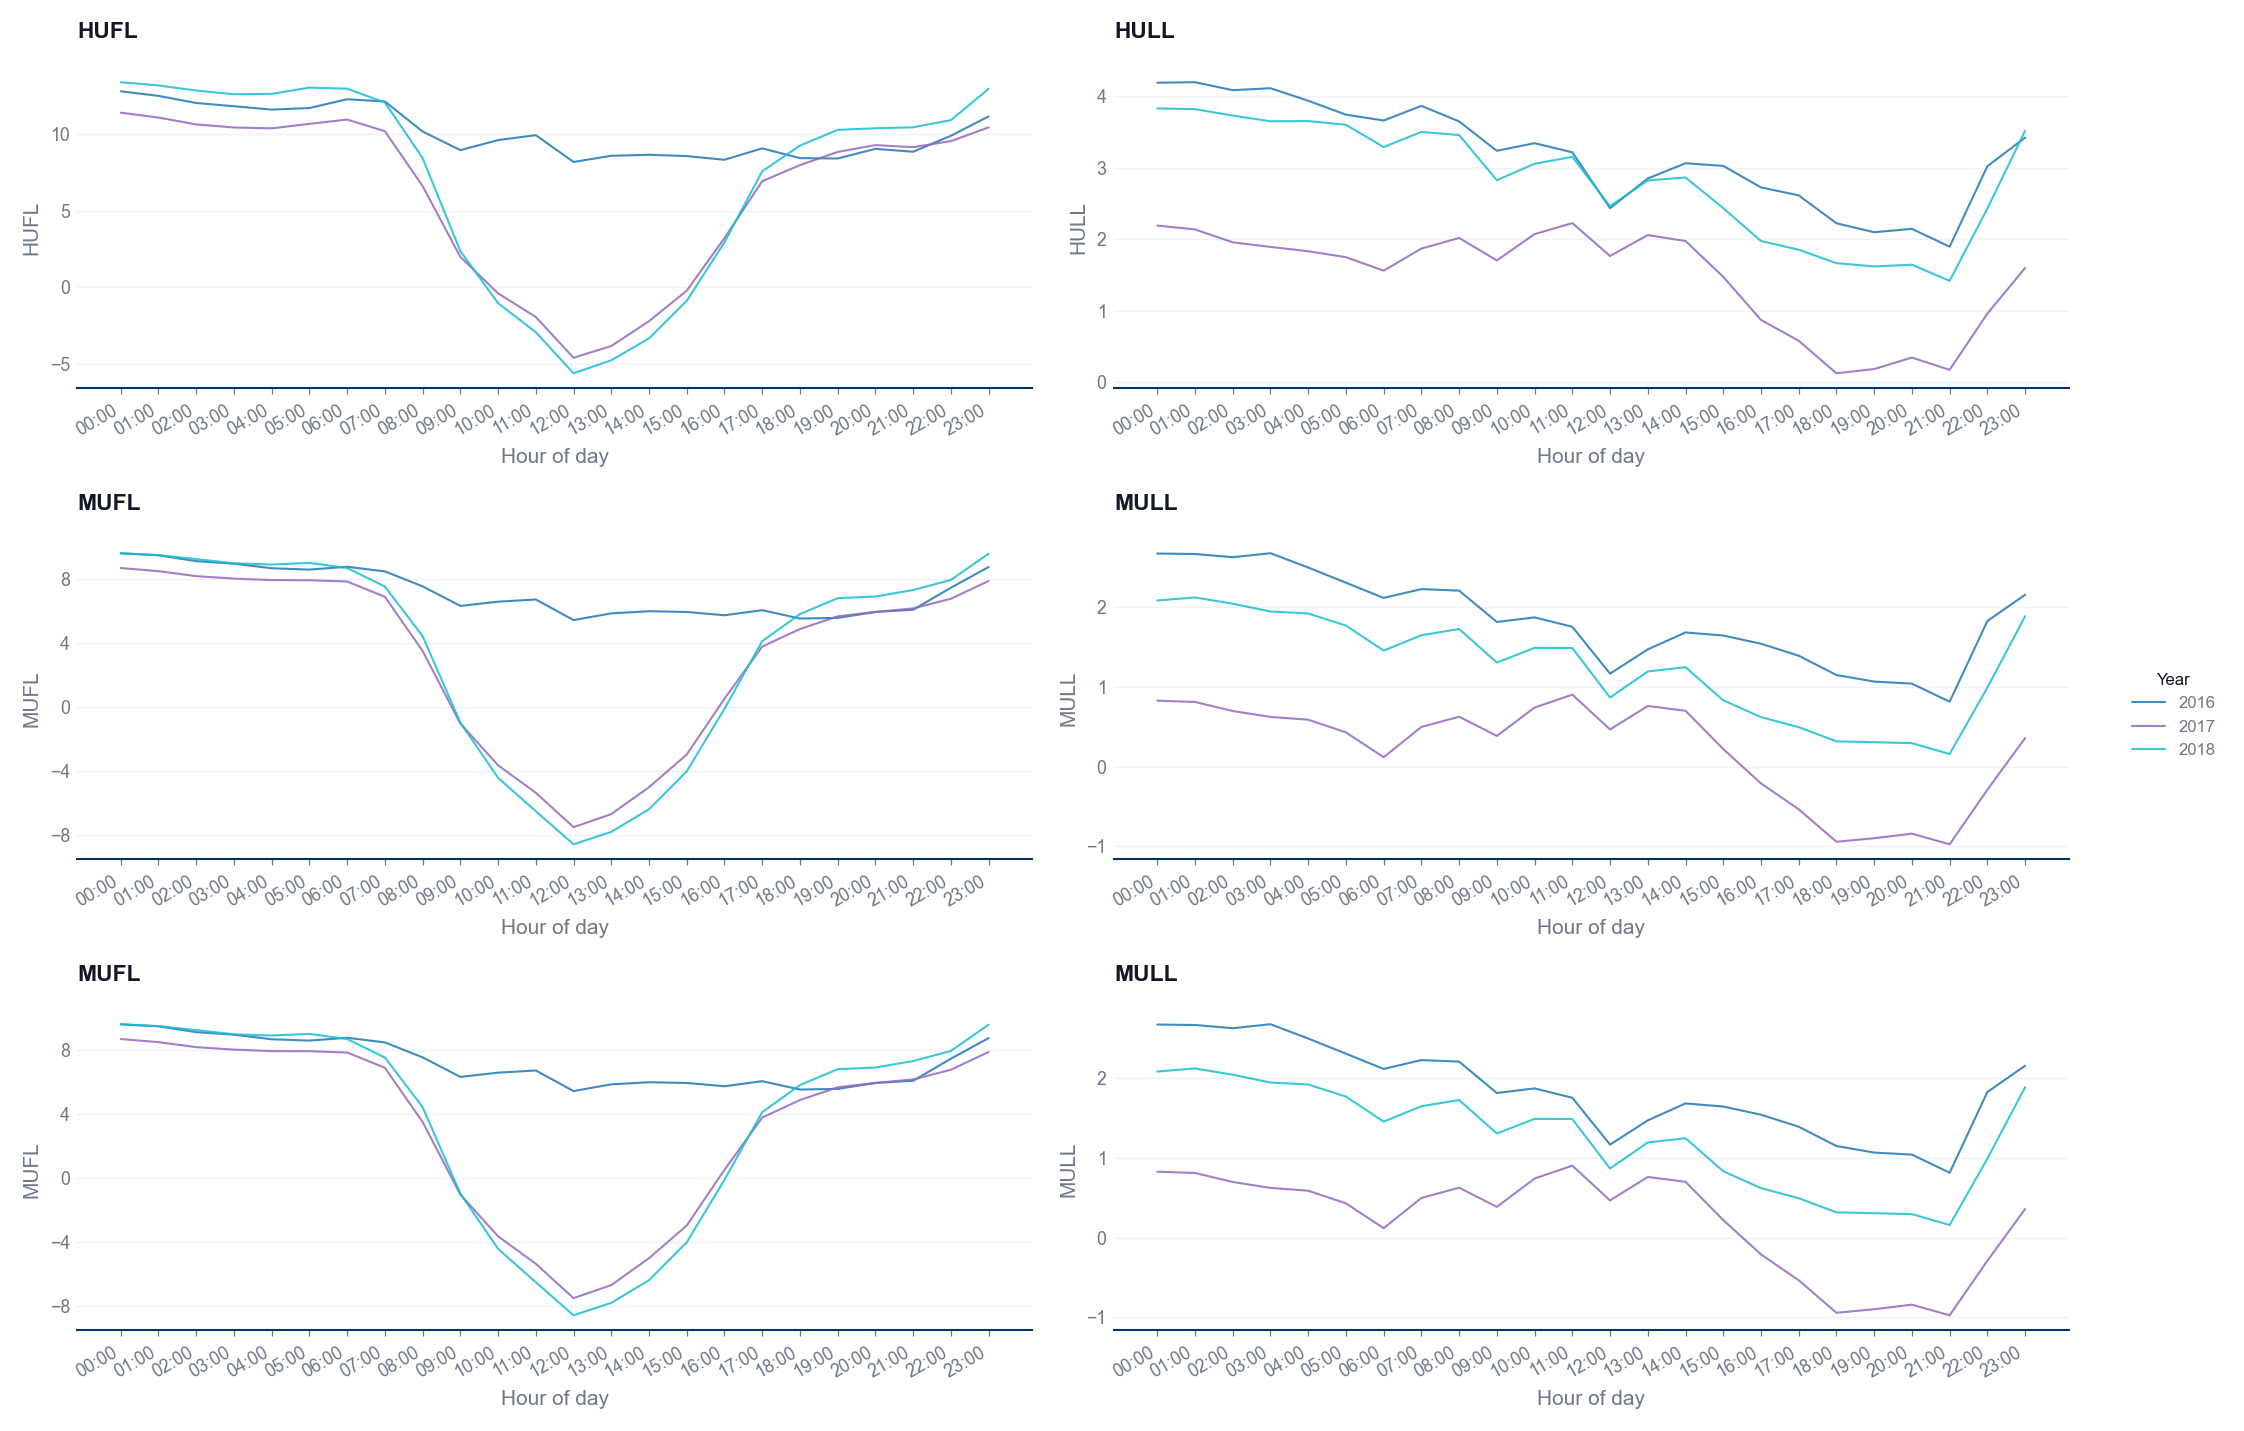

In [17]:
fig = plot_seasonal_grid(df, ["HUFL", "HULL", "MUFL", "MULL", "MUFL", "MULL"], season="year", period="hour", rows=3, cols=2)

### 3.2.2 Indepdent Variable

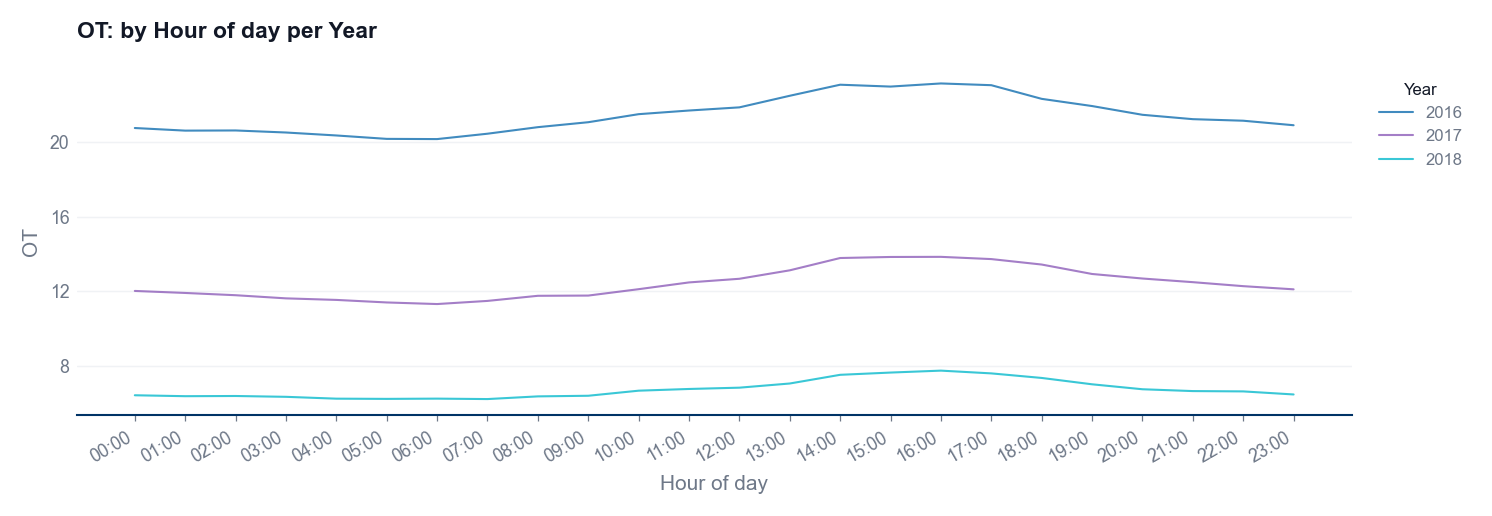

In [18]:
fig = plot_seasonal(df, "OT", season="year", period="hour")

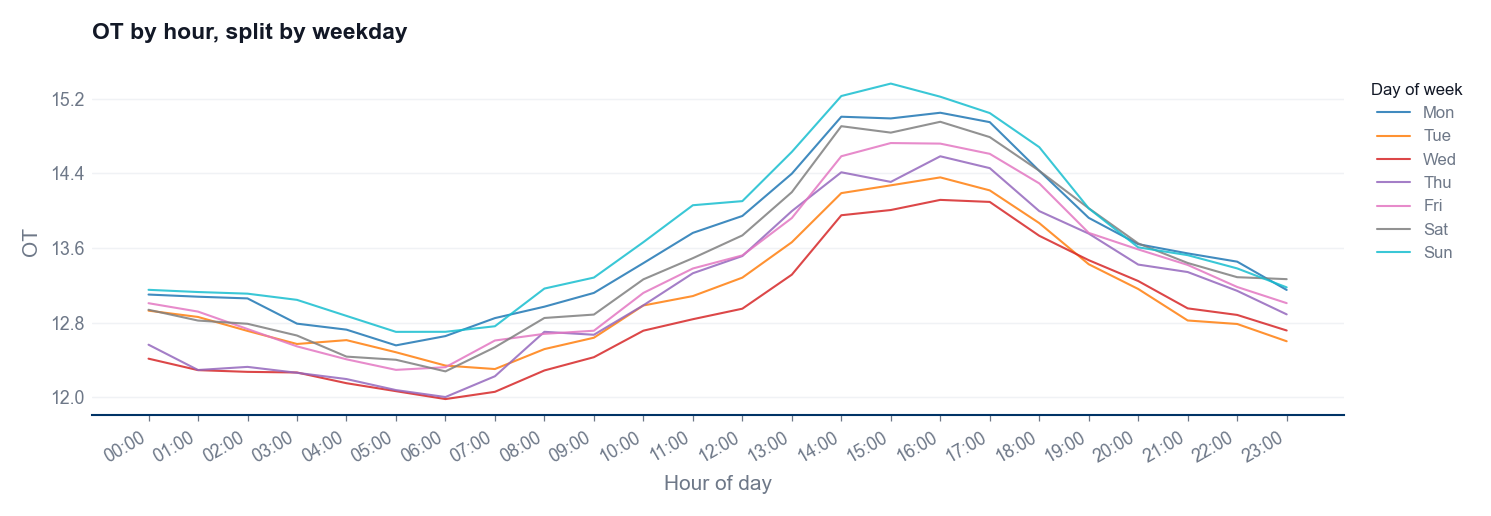

In [19]:
fig = plot_seasonal(df, "OT", season="dayofweek", period="hour", title="OT by hour, split by weekday")

## 3.3 Boxplots

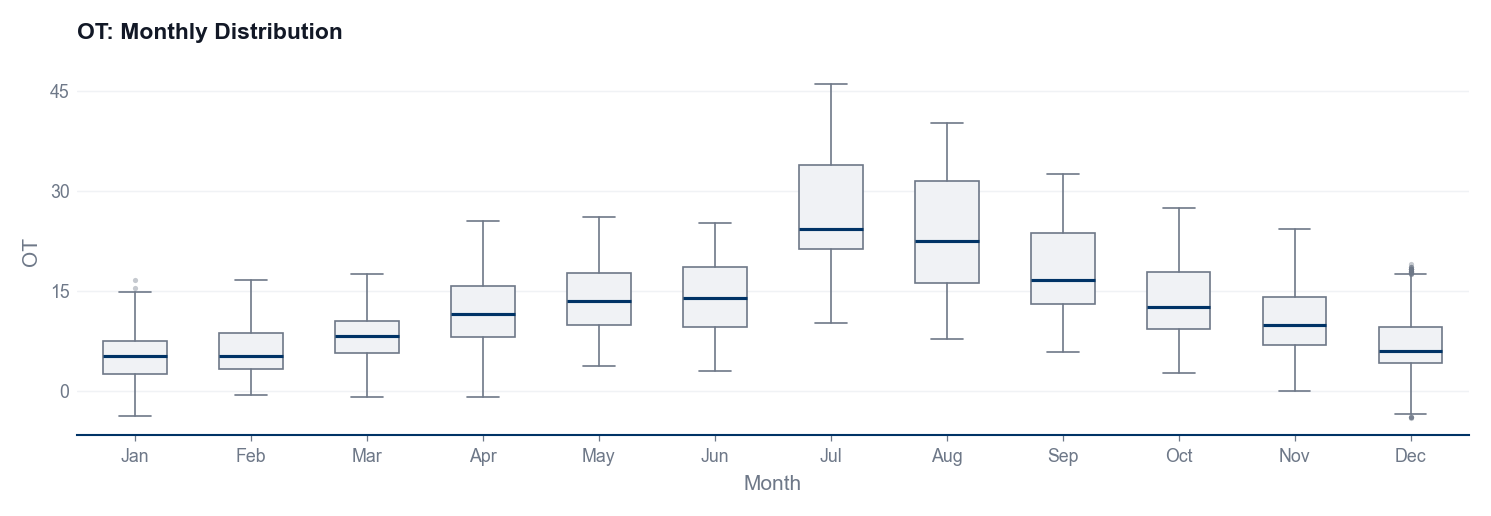

In [20]:
fig = plot_monthly_box(df, "OT")

---

# 4 Lag Analysis
---
- ACF shows seaonality at 96 lags (24 hours) for many features.
- ACF shows OT has very strong memory.
- PACF plot suggests LOCF will perform well.



## 4.1 ACF

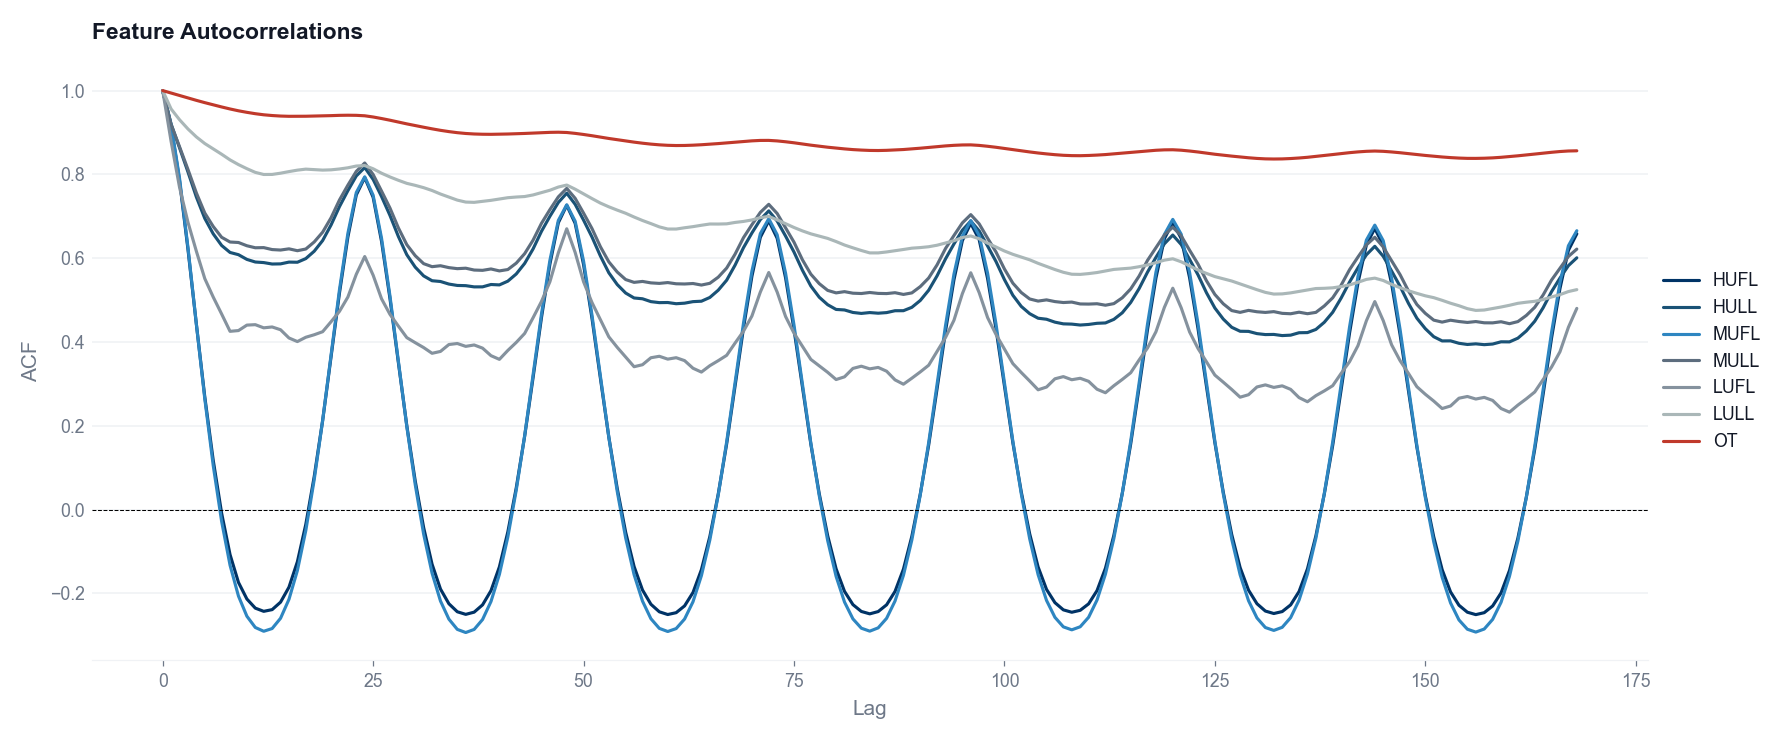

In [21]:
from statsmodels.tsa.stattools import acf

lags = 168
fig, ax = plt.subplots(figsize=(12, 5))
FEATURES = df.columns

for feature in FEATURES:
    acf_vals = acf(df[feature], nlags=lags, fft=True)
    ax.plot(acf_vals, label=feature, linewidth=1.5, color=FEATURE_COLOURS[feature])

ax.axhline(0, color='black', linewidth=0.5, linestyle='--')
ax.set_title("Feature Autocorrelations", loc="left")
ax.set_xlabel("Lag")
ax.set_ylabel("ACF")
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

## 4.2 PACF

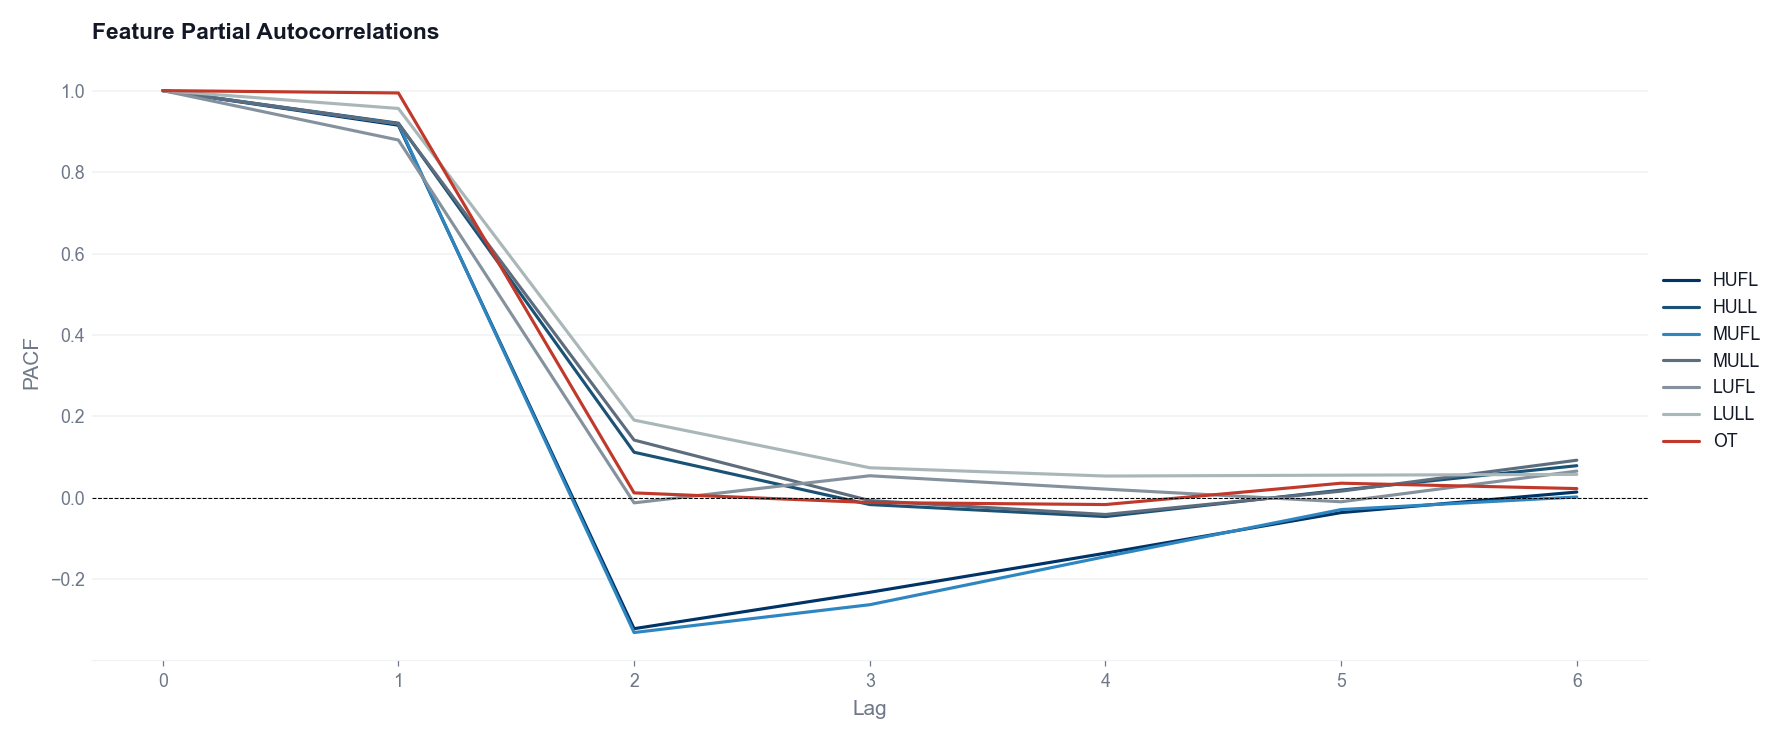

In [22]:
from statsmodels.tsa.stattools import pacf

lags = 6
fig, ax = plt.subplots(figsize=(12, 5))
FEATURES = df.columns

for feature in FEATURES:
    pacf_vals = pacf(df[feature], nlags=lags)
    ax.plot(pacf_vals, label=feature, linewidth=1.5, color=FEATURE_COLOURS[feature])

ax.axhline(0, color='black', linewidth=0.5, linestyle='--')
ax.set_title("Feature Partial Autocorrelations", loc="left")
ax.set_xlabel("Lag")
ax.set_ylabel("PACF")
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

---

# 5 Time Series Decomposition
---

## 5.1 STL Decomposition

In [23]:
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller

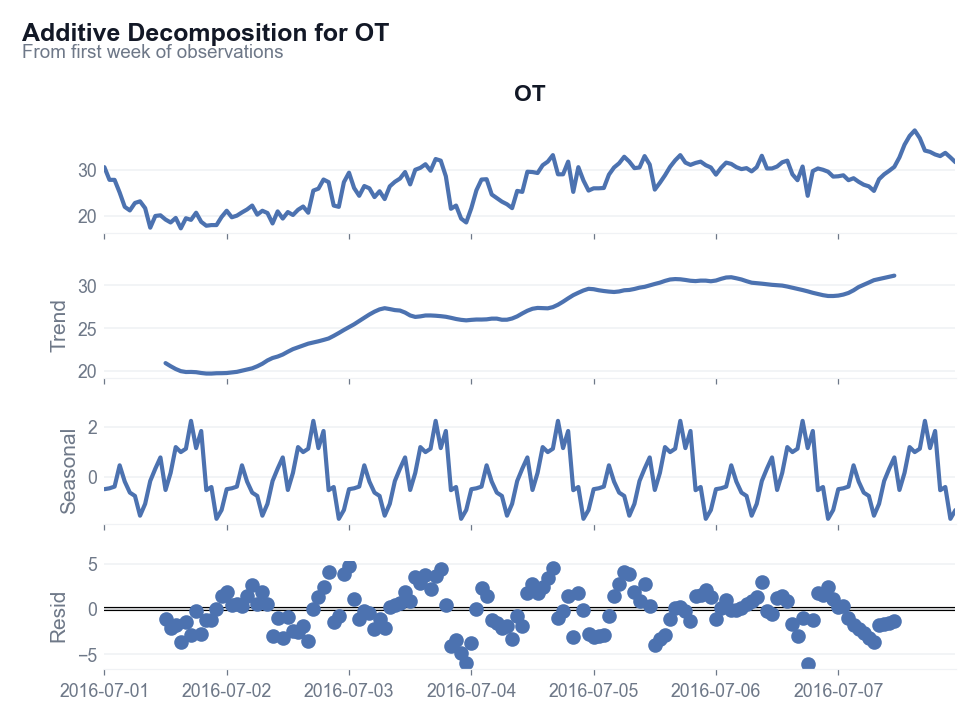

In [24]:
decompOT = seasonal_decompose(df.iloc[:168].OT, model="additive", period=24)
fig = decompOT.plot()
fig.suptitle("Additive Decomposition for OT", x=0.0, ha="left", fontsize=12, fontweight="bold")
fig.text(0.0, 0.95, "From first week of observations", ha="left", fontsize=9, color=MUTED, va="top")
plt.tight_layout()
plt.show()

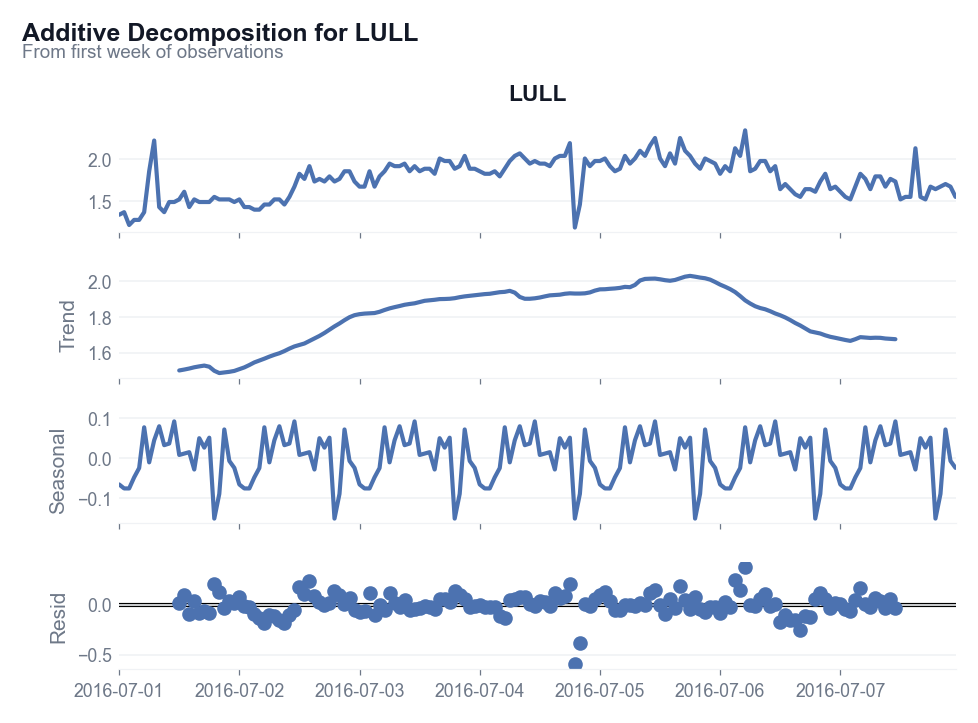

In [25]:
decompLULL = seasonal_decompose(df.iloc[:168].LULL, model="additive", period=24)

fig = decompLULL.plot()

fig.suptitle("Additive Decomposition for LULL", x=0.0, ha="left", fontsize=12, fontweight="bold")
fig.text(0.0, 0.95, "From first week of observations", ha="left", fontsize=9, color=MUTED, va="top")
plt.tight_layout()
plt.show()

In [26]:
from statsmodels.tsa.seasonal import STL

stl = STL(df.OT, period=168, robust=False)
res_stl = stl.fit()
dcmp = pd.DataFrame({
    "datetime": df.index,
    "data": df.OT,
    "trend": res_stl.trend,
    "seasonal": res_stl.seasonal,
    "remainder": res_stl.resid
}).set_index("datetime")

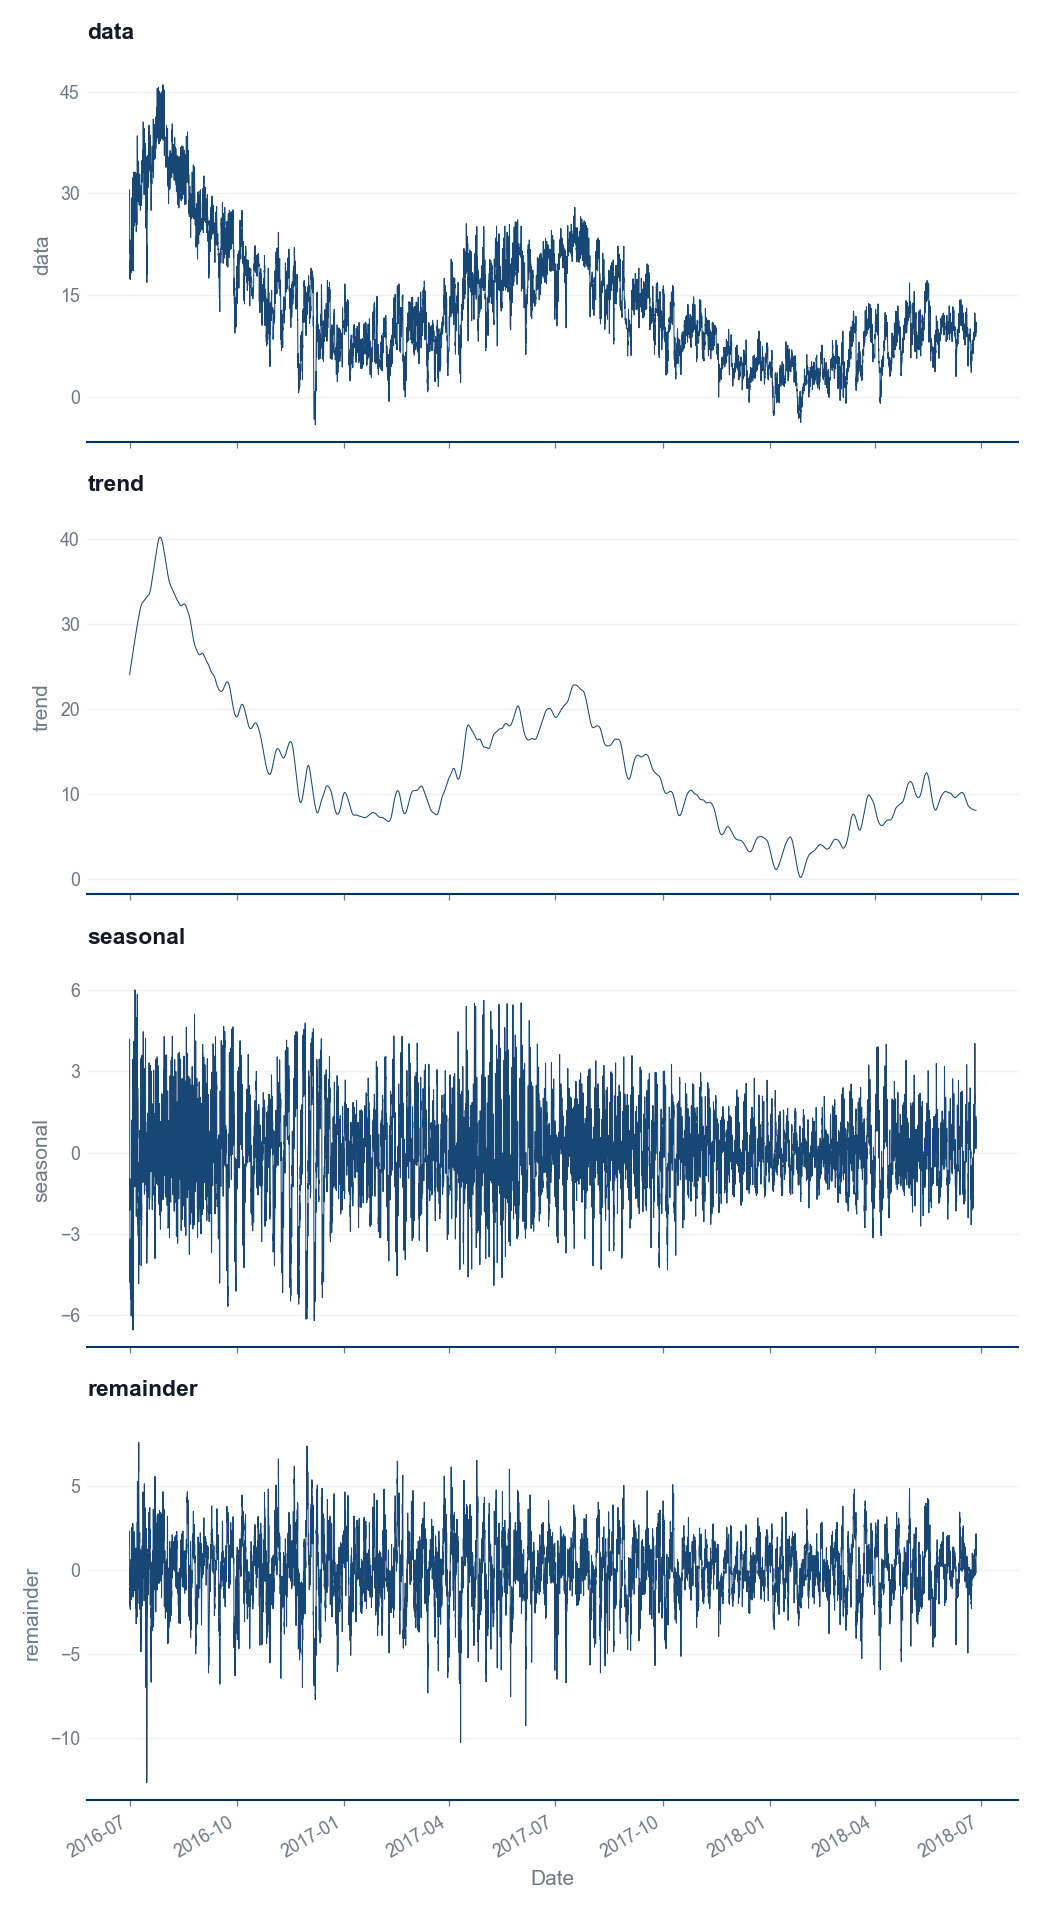

In [27]:
plot_features_ts(dcmp, ["data", "trend", "seasonal", "remainder"], rows=4, cols=1)
plt.show()

## 5.2 Time Series Features

### 5.2.1 ACF Features

## 5.3 Moving Average

In [28]:
df_ma = df.copy()

In [29]:
df_ma["OT-24-MA"] = df.OT.rolling(window=24, center=True).mean()
df_ma["OT-2x24-MA"] = df_ma["OT-24-MA"].rolling(window=2, center=True).mean()
df.head(100)

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
date,,,,,,,
2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000
...,...,...,...,...,...,...,...
2016-07-04 23:00:00,12.726,6.497,9.346,3.482,3.168,1.980,25.466000
2016-07-05 00:00:00,11.989,5.626,8.777,2.949,3.198,1.980,25.958000
2016-07-05 01:00:00,12.525,6.296,8.955,3.163,3.137,2.010,25.958000


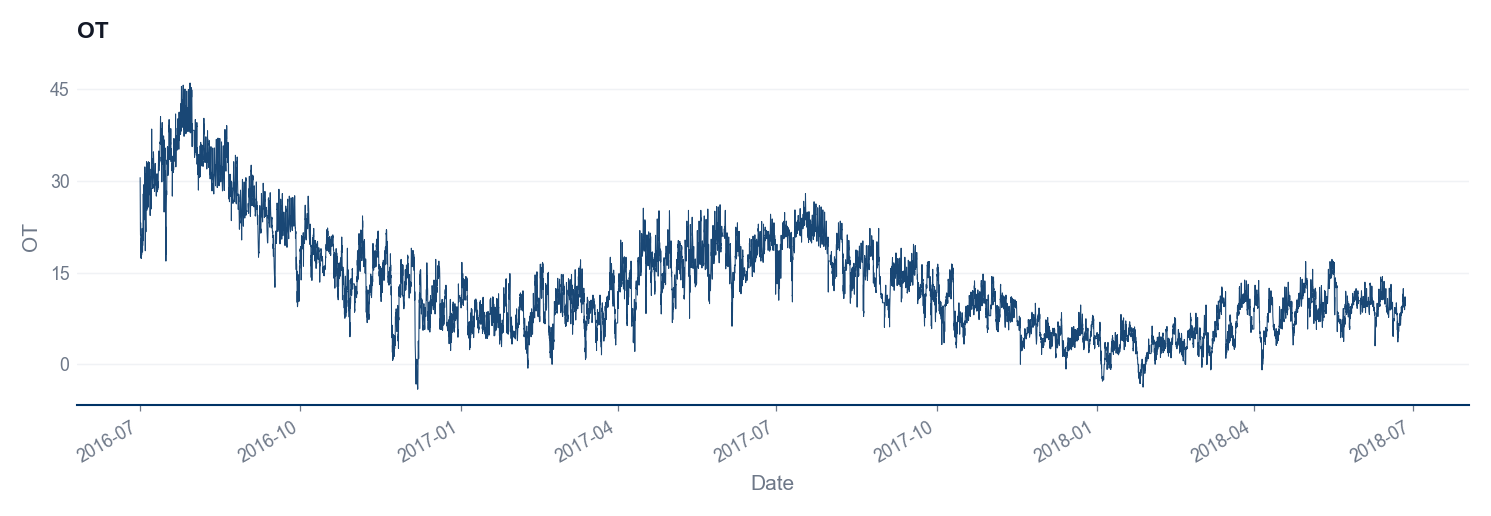

In [30]:
plot_feature_ts(df, "OT")
plt.show()

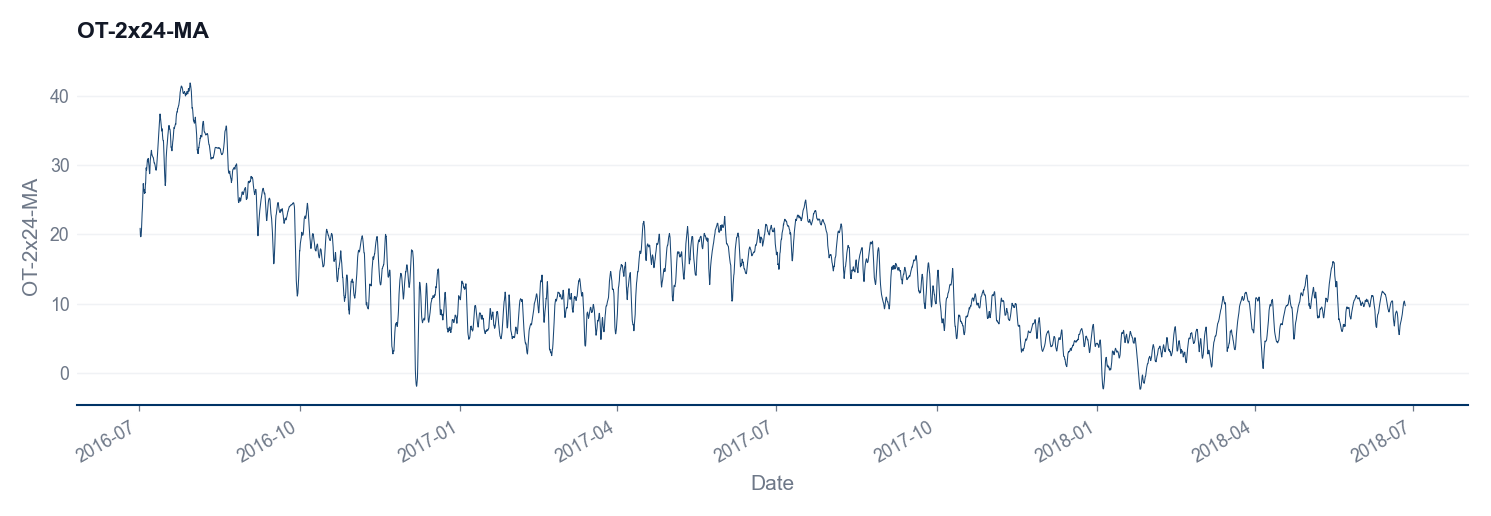

In [31]:
plot_feature_ts(df_ma, feature="OT-2x24-MA")
plt.show()

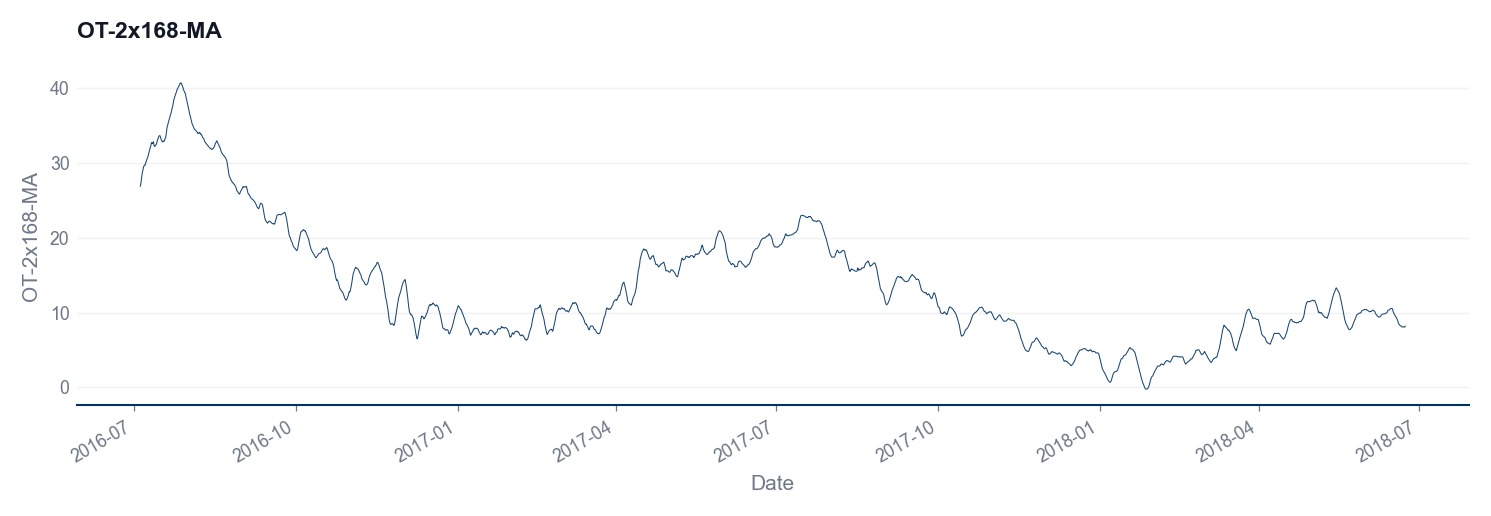

In [32]:
df_ma["OT-168-MA"] = df.OT.rolling(window=168, center=True).mean()
df_ma["OT-2x168-MA"] = df_ma["OT-168-MA"].rolling(window=2, center=True).mean()
plot_feature_ts(df_ma, feature="OT-2x168-MA")
plt.show()

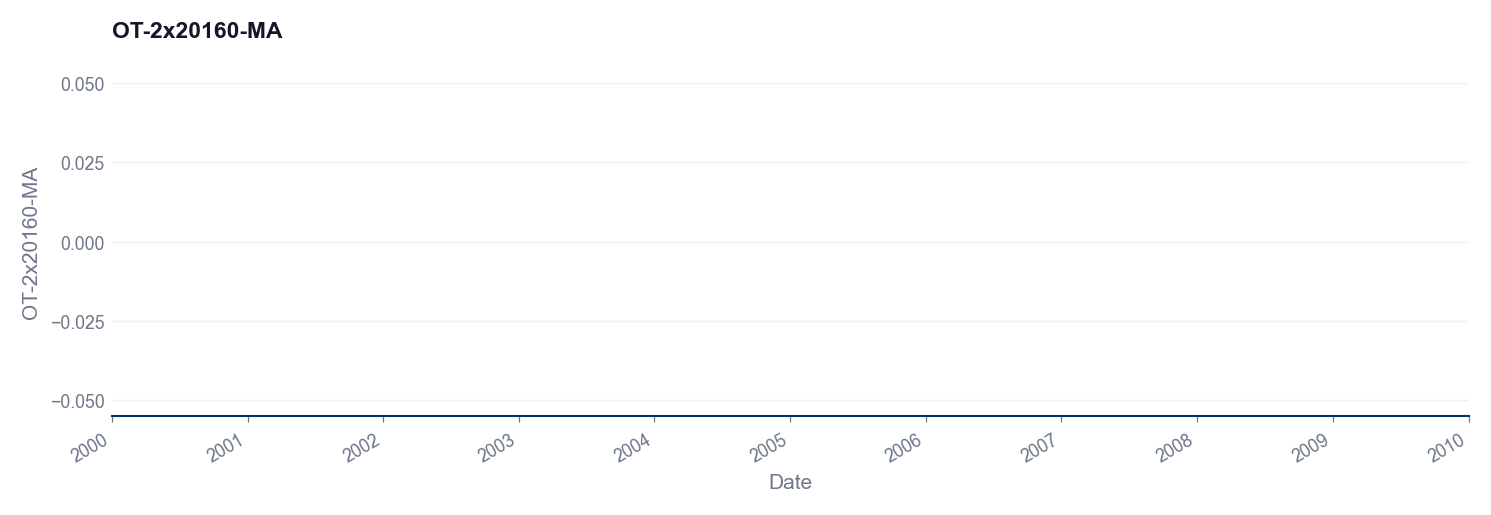

In [33]:
df_ma["OT-20160-MA"] = df.OT.rolling(window=20160, center=True).mean()
df_ma["OT-2x20160-MA"] = df_ma["OT-20160-MA"].rolling(window=2, center=True).mean()
plot_feature_ts(df_ma, feature="OT-2x20160-MA")
plt.show()

# 6 Stationarity Testing
---

## 6.1 Differencing

In [44]:
diffed = df.copy()

Difference all features by 1 season e.g. by 24.

In [45]:
for col in diffed.columns:
    diffed[col] = diffed[col].diff(24)

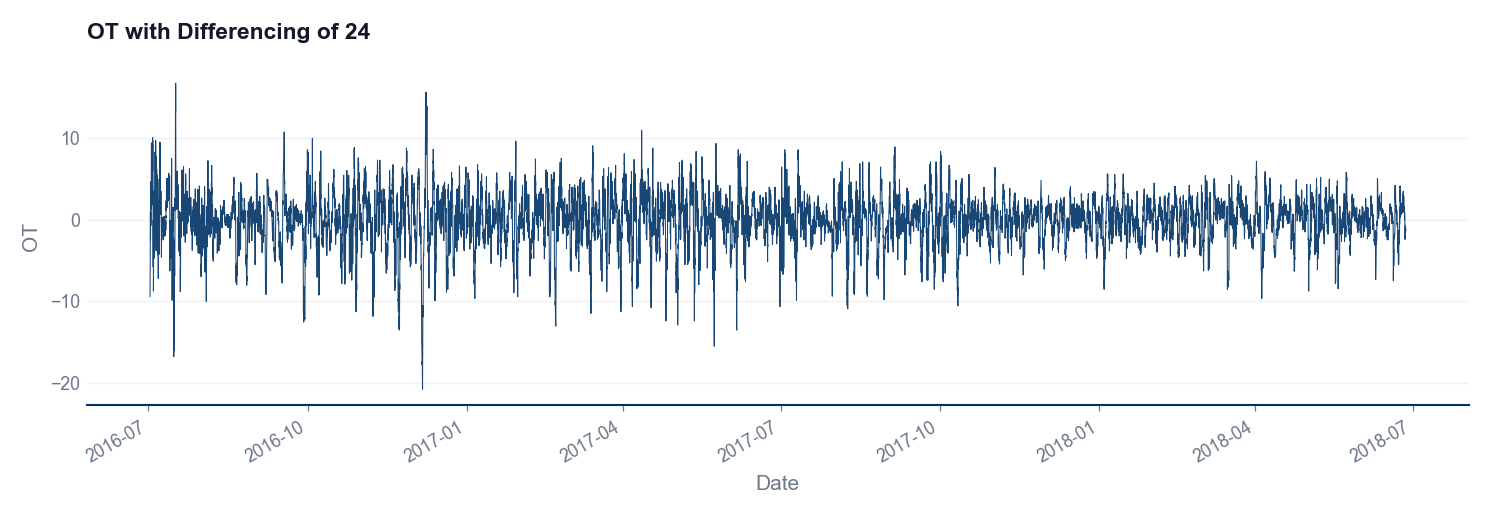

In [54]:
plot_feature_ts(diffed, "OT", title="OT with Differencing of 24")
plt.show()

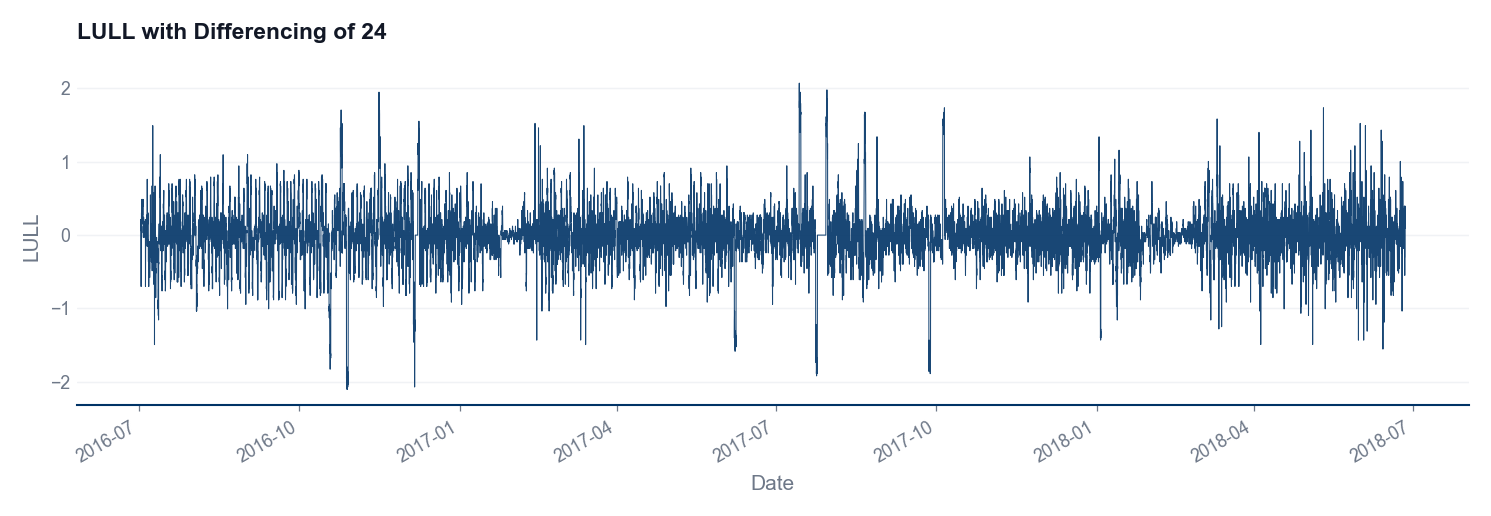

In [55]:
plot_feature_ts(diffed, "LULL", title="LULL with Differencing of 24")
plt.show()

In [57]:
diffed

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
date,,,,,,,
2016-07-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-07-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-07-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-07-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-07-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
2018-06-26 15:00:00,6.765000,-0.335,5.614,0.000,0.365,0.091,-0.703000
2018-06-26 16:00:00,-4.286000,1.072,-4.299,0.639,0.578,0.396,-1.337000
2018-06-26 17:00:00,-1.809000,0.737,-2.700,0.462,0.061,0.274,-1.196000


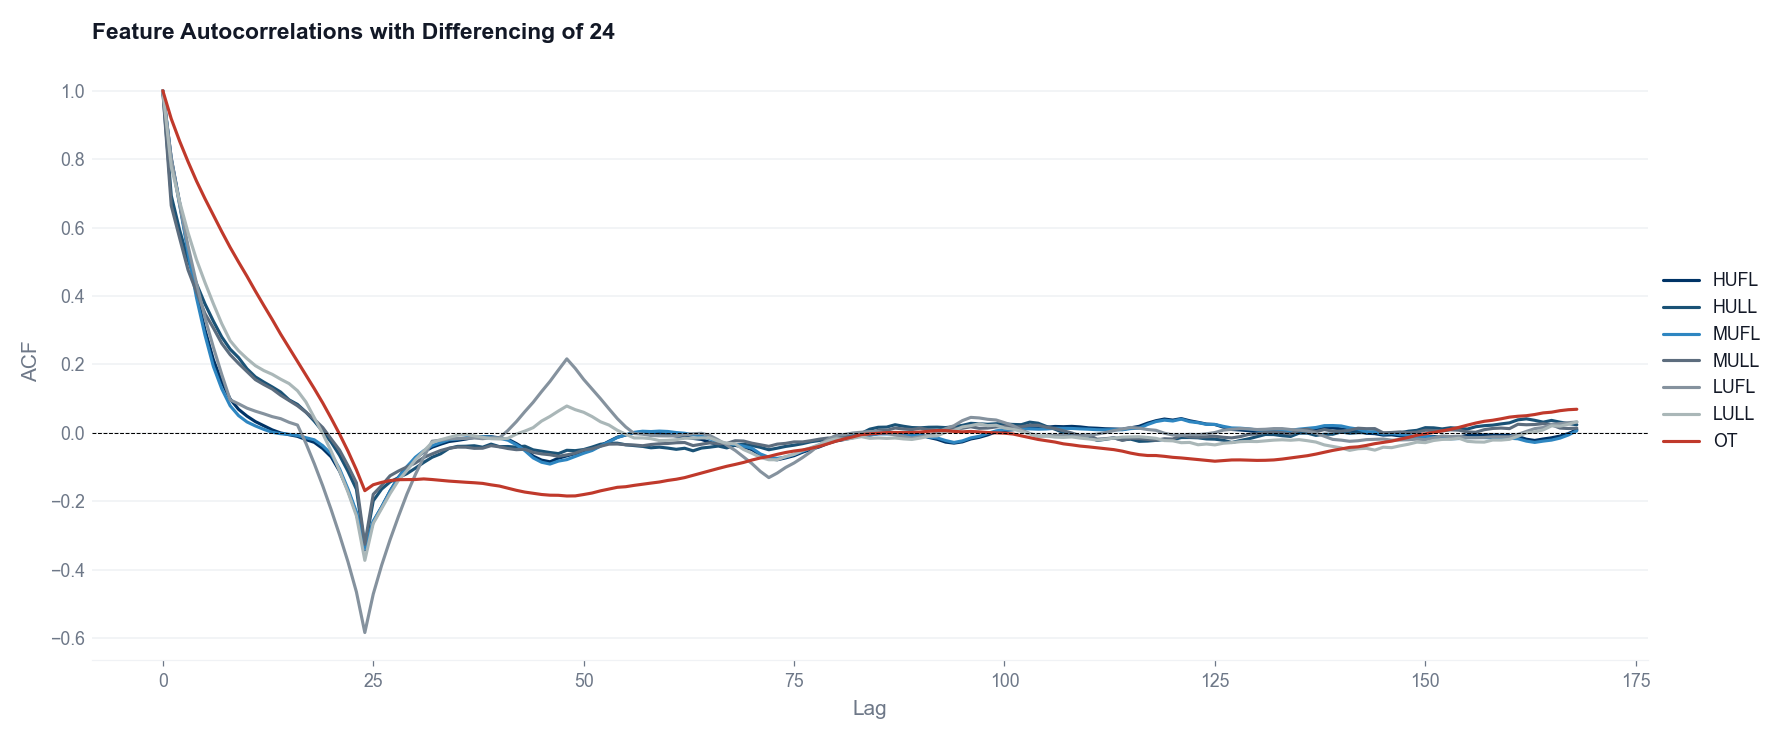

In [ ]:
from statsmodels.tsa.stattools import acf

fig, ax = plt.subplots(figsize=(12, 5))
FEATURES = diffed.columns

for feature in FEATURES:
    acf_vals = acf(diffed[feature].dropna(), nlags=168, fft=True)
    ax.plot(acf_vals, label=feature, linewidth=1.5, color=FEATURE_COLOURS[feature])

ax.axhline(0, color='black', linewidth=0.5, linestyle='--')
ax.set_title("Feature Autocorrelations with Differencing of 24", loc="left")
ax.set_xlabel("Lag")
ax.set_ylabel("ACF")
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

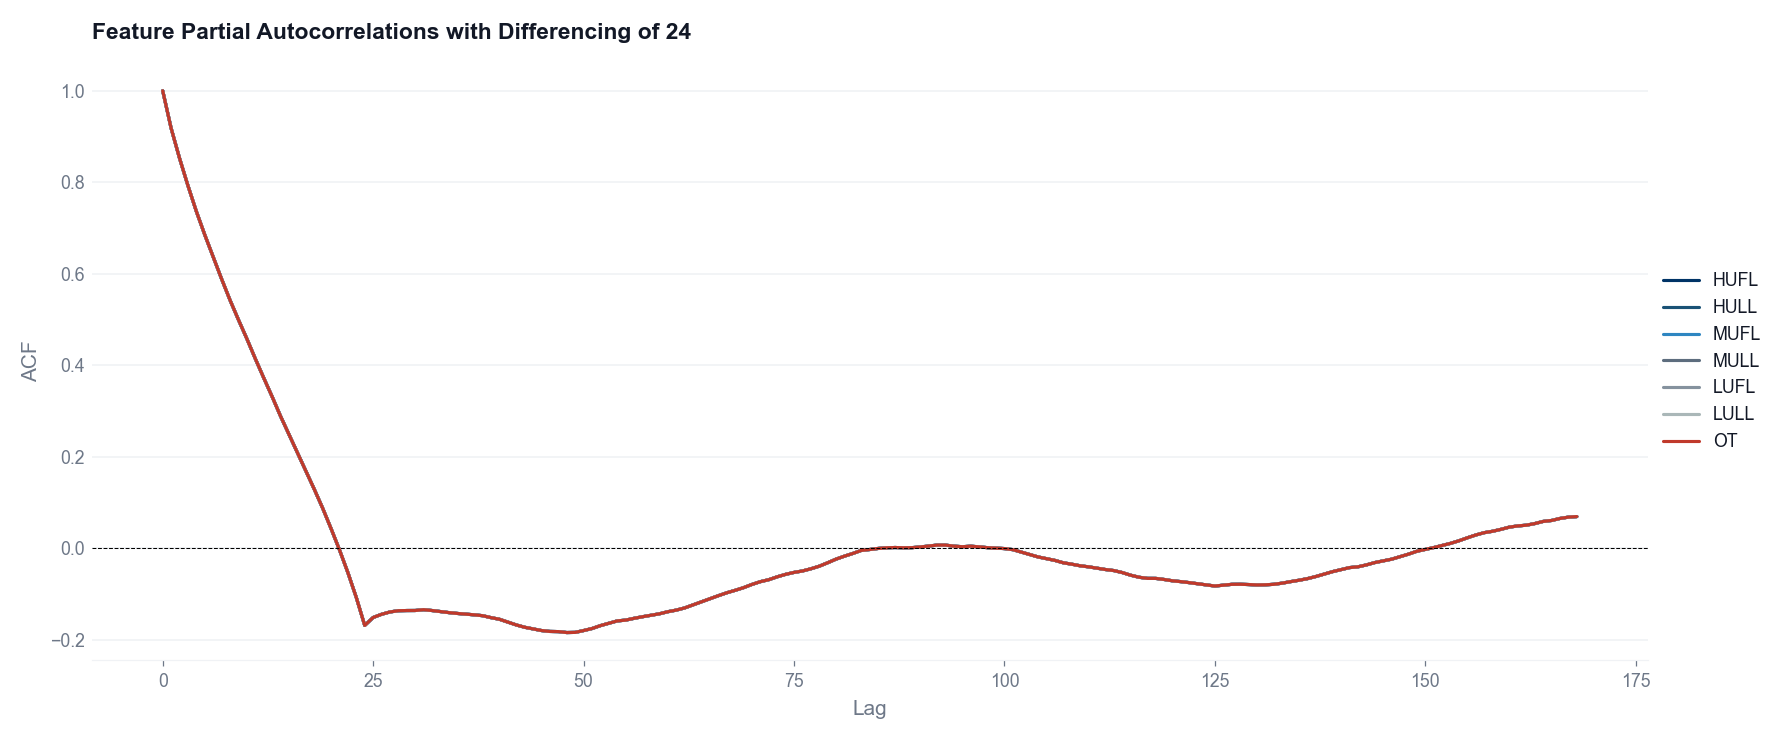

In [64]:
from statsmodels.tsa.stattools import pacf

fig, ax = plt.subplots(figsize=(12, 5))
FEATURES = diffed.columns

for feature in FEATURES:
    pacf_vals = pacf(diffed[feature].dropna(), nlags=168)
    ax.plot(acf_vals, label=feature, linewidth=1.5, color=FEATURE_COLOURS[feature])

ax.axhline(0, color='black', linewidth=0.5, linestyle='--')
ax.set_title("Feature Partial Autocorrelations with Differencing of 24", loc="left")
ax.set_xlabel("Lag")
ax.set_ylabel("ACF")
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

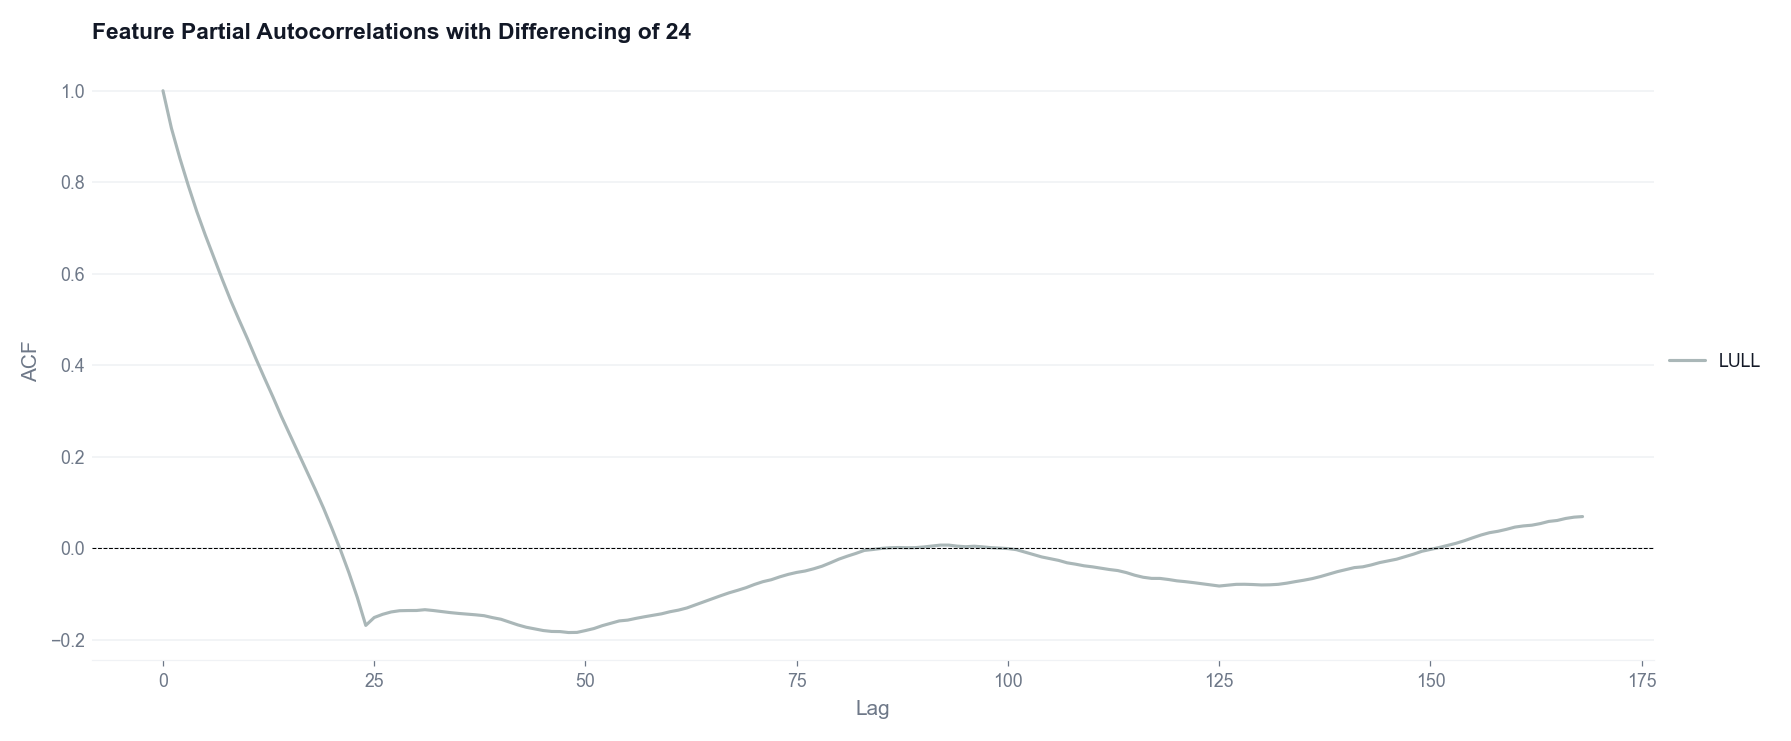

In [63]:
from statsmodels.tsa.stattools import pacf

fig, ax = plt.subplots(figsize=(12, 5))
FEATURES = diffed.columns

for feature in ["LULL"]:
    pacf_vals = pacf(diffed[feature].dropna(), nlags=168)
    ax.plot(acf_vals, label=feature, linewidth=1.5, color=FEATURE_COLOURS[feature])

ax.axhline(0, color='black', linewidth=0.5, linestyle='--')
ax.set_title("Feature Partial Autocorrelations with Differencing of 24", loc="left")
ax.set_xlabel("Lag")
ax.set_ylabel("ACF")
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()